In [2]:
import pandas as pd

print(pd.__version__)

3.0.5


In [3]:
df = pd.read_csv("../data/raw/Reviews.csv")

In [4]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [5]:
df.shape

(568454, 10)

In [6]:
df.columns.tolist()

['Id',
 'ProductId',
 'UserId',
 'ProfileName',
 'HelpfulnessNumerator',
 'HelpfulnessDenominator',
 'Score',
 'Time',
 'Summary',
 'Text']

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 313.1 MB


# Data Dictionary

| Column | Description | Data Type | Role |
|---|---|---|---|
| Id | Unique identifier for the review record | Integer | Identifier |
| ProductId | Identifier of the reviewed product | String | Product information |
| UserId | Identifier of the reviewer | String | User information |
| ProfileName | Name associated with the reviewer profile | String | User information |
| HelpfulnessNumerator | Number of users who found the review helpful | Integer | Review quality |
| HelpfulnessDenominator | Total number of users who rated the review's helpfulness | Integer | Review quality |
| Score | Product rating given by the reviewer, from 1 to 5 | Integer | Target / rating |
| Time | Unix timestamp representing when the review was created | Integer | Time |
| Summary | Short summary/title written by the reviewer | String | Text feature |
| Text | Full review written by the reviewer | String | Primary text feature |

 **Note:** HelpfulnessNumerator and HelpfulnessDenominator are only meaningful together as a ratio (helpfulness_ratio) — individually they don't indicate review quality

In [8]:
df.dtypes

Id                        int64
ProductId                   str
UserId                      str
ProfileName                 str
HelpfulnessNumerator      int64
HelpfulnessDenominator    int64
Score                     int64
Time                      int64
Summary                     str
Text                        str
dtype: object

In [9]:
df.nunique()

Id                        568454
ProductId                  74258
UserId                    256059
ProfileName               218415
HelpfulnessNumerator         231
HelpfulnessDenominator       234
Score                          5
Time                        3168
Summary                   295742
Text                      393579
dtype: int64

In [10]:
df["Score"].value_counts().sort_index()

Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64

# 3. Data Quality Checks

In [11]:
df.isnull().sum()

Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

In [12]:
df.isnull().sum().sort_values(ascending=False)

Summary                   27
ProfileName               26
ProductId                  0
Id                         0
HelpfulnessNumerator       0
UserId                     0
HelpfulnessDenominator     0
Score                      0
Time                       0
Text                       0
dtype: int64

In [ ]:
# True duplicate check: same user, same time, same review text
dup_count = df.duplicated(subset=['UserId', 'Time', 'Text']).sum()
print('True duplicates found:', dup_count)

# Drop duplicates, keep the first occurrence
before = len(df)
df = df.drop_duplicates(subset=['UserId', 'Time', 'Text'], keep='first')
print('Rows before:', before, '-> after dedup:', len(df))

# Remove rows where helpfulness data is broken (numerator > denominator)
bad = df[df['HelpfulnessNumerator'] > df['HelpfulnessDenominator']]
print('Broken helpfulness rows:', len(bad))
df = df[~df.index.isin(bad.index)]
print('Final clean row count:', len(df))

,UserId,ProductId,Time,Text
83317,#oc-R115TNMSPFT9I7,B005ZBZLT4,1331510400,Overall its just OK when considering the price...
180871,#oc-R115TNMSPFT9I7,B007Y59HVM,1331510400,Overall its just OK when considering the price...
290947,#oc-R11D9D7SHXIJB9,B005HG9ESG,1342396800,"My wife has recurring extreme muscle spasms, u..."
455533,#oc-R11D9D7SHXIJB9,B005HG9ERW,1342396800,"My wife has recurring extreme muscle spasms, u..."
496893,#oc-R11D9D7SHXIJB9,B005HG9ET0,1342396800,"My wife has recurring extreme muscle spasms, u..."
83656,#oc-R11DNU2NBKQ23Z,B005ZBZLT4,1348531200,This coffee is horrible and unfortunately not ...
181210,#oc-R11DNU2NBKQ23Z,B007Y59HVM,1348531200,This coffee is horrible and unfortunately not ...
290773,#oc-R11O5J5ZVQE25C,B005HG9ESG,1346889600,This will be the bottle that you grab from the...
455359,#oc-R11O5J5ZVQE25C,B005HG9ERW,1346889600,This will be the bottle that you grab from the...
496719,#oc-R11O5J5ZVQE25C,B005HG9ET0,1346889600,This will be the bottle that you grab from the...


In [14]:
df["Text"].nunique()

393579

In [15]:
df["Score"].value_counts().sort_index()
df["Score"].min(), df["Score"].max()

(np.int64(1), np.int64(5))

In [16]:
df[~df["Score"].isin([1, 2, 3, 4, 5])].shape

(0, 10)

In [17]:
df[["HelpfulnessNumerator", "HelpfulnessDenominator"]].describe()

,HelpfulnessNumerator,HelpfulnessDenominator
count,568454.000000,568454.00000
mean,1.743817,2.22881
std,7.636513,8.28974
min,0.000000,0.00000
25%,0.000000,0.00000
50%,0.000000,1.00000
75%,2.000000,2.00000
max,866.000000,923.00000


In [18]:
(df["HelpfulnessNumerator"] > df["HelpfulnessDenominator"]).sum()


np.int64(2)

In [19]:
df["HelpfulnessDenominator"].value_counts().head(10)

HelpfulnessDenominator
0    270052
1    112753
2     61482
3     34394
4     22306
5     14824
6     10378
7      7461
8      5416
9      4406
Name: count, dtype: int64

# 4. Feature Engineering

In [20]:
df["date"] = pd.to_datetime(df["Time"], unit="s")
df[["Time", "date"]].head()

,Time,date
0,1303862400,2011-04-27
1,1346976000,2012-09-07
2,1219017600,2008-08-18
3,1307923200,2011-06-13
4,1350777600,2012-10-21


In [21]:
df["review_year"] = df["date"].dt.year
df["review_month"] = df["date"].dt.month
df[["date", "review_year", "review_month"]].head()

,date,review_year,review_month
0,2011-04-27,2011,4
1,2012-09-07,2012,9
2,2008-08-18,2008,8
3,2011-06-13,2011,6
4,2012-10-21,2012,10


In [22]:
df["review_length"] = df["Text"].fillna("").str.len()
df["review_length"].describe()

count    568454.000000
mean        436.222083
std         445.339741
min          12.000000
25%         179.000000
50%         302.000000
75%         527.000000
max       21409.000000
Name: review_length, dtype: float64

In [23]:
df["summary_length"] = df["Summary"].fillna("").str.len()
df["summary_length"].describe()

count    568454.000000
mean         23.445744
std          14.028662
min           0.000000
25%          13.000000
50%          20.000000
75%          30.000000
max         128.000000
Name: summary_length, dtype: float64

In [24]:
df["helpfulness_ratio"] = (
    df["HelpfulnessNumerator"]
    / df["HelpfulnessDenominator"].replace(0, pd.NA)
)
df["helpfulness_ratio"].describe()
df[[
    "HelpfulnessNumerator",
    "HelpfulnessDenominator",
    "helpfulness_ratio"
]].head(10)

,HelpfulnessNumerator,HelpfulnessDenominator,helpfulness_ratio
0,1,1,1.0
1,0,0,<NA>
2,1,1,1.0
3,3,3,1.0
4,0,0,<NA>
5,0,0,<NA>
6,0,0,<NA>
7,0,0,<NA>
8,1,1,1.0
9,0,0,<NA>


In [25]:
# Derive sentiment_label from Score (1-2: negative, 3: neutral, 4-5: positive)
def assign_sentiment(score):
    if score > 3:
        return "positive"
    elif score < 3:
        return "negative"
    else:
        return "neutral"

df["sentiment_label"] = df["Score"].apply(assign_sentiment)

# Optional: Fill NA helpfulness ratio with 0.0 for easier numerical modeling later
df["helpfulness_ratio"] = df["helpfulness_ratio"].fillna(0.0)

# Save processed dataframe
df.to_csv("../data/processed/reviews_cleaned.csv", index=False)

# 5. Exploratory Data Analysis

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

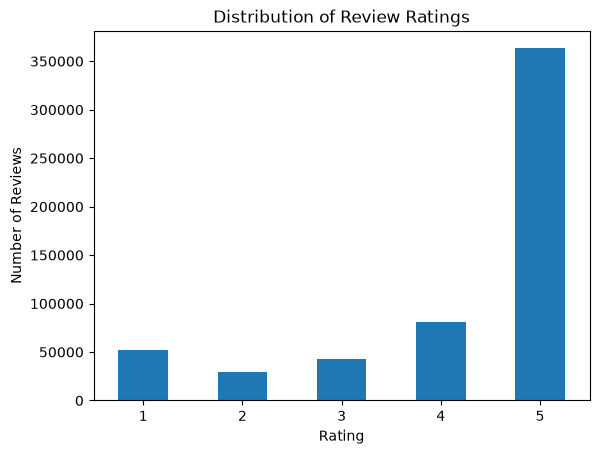

In [27]:
score_counts = df["Score"].value_counts().sort_index()

score_counts.plot(kind="bar")

plt.title("Distribution of Review Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

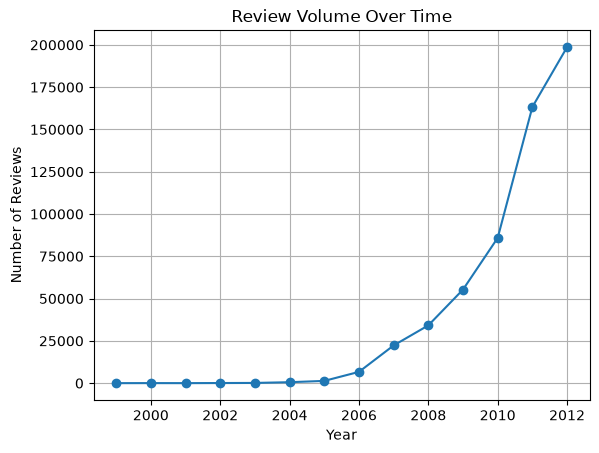

In [28]:
reviews_by_year = df.groupby("review_year").size()

reviews_by_year
reviews_by_year.plot(kind="line", marker="o")

plt.title("Review Volume Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Reviews")
plt.grid(True)
plt.show()

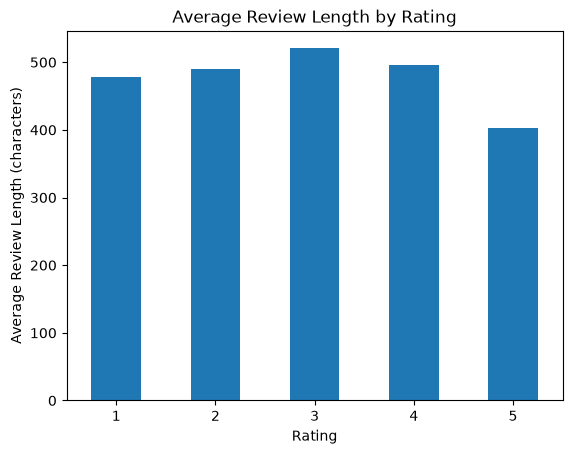

In [29]:
df.groupby("Score")["review_length"].mean()
df.groupby("Score")["review_length"].mean().plot(kind="bar")

plt.title("Average Review Length by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Review Length (characters)")
plt.xticks(rotation=0)
plt.show()

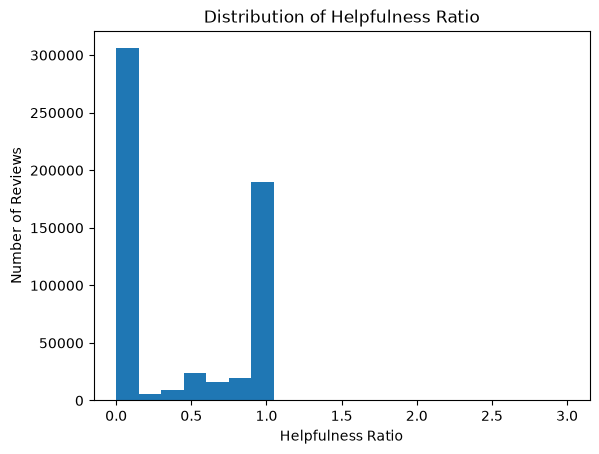

In [30]:
df["helpfulness_ratio"].describe()
df["helpfulness_ratio"].dropna().plot(kind="hist", bins=20)

plt.title("Distribution of Helpfulness Ratio")
plt.xlabel("Helpfulness Ratio")
plt.ylabel("Number of Reviews")
plt.show()

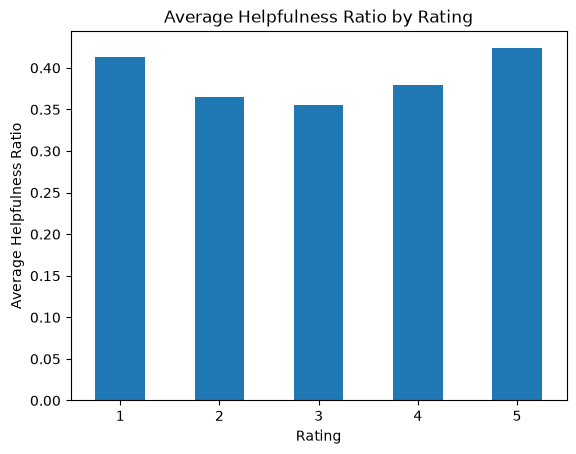

In [31]:
df.groupby("Score")["helpfulness_ratio"].mean()
df.groupby("Score")["helpfulness_ratio"].mean().plot(kind="bar")

plt.title("Average Helpfulness Ratio by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Helpfulness Ratio")
plt.xticks(rotation=0)
plt.show()

Insight 1 — Rating distribution

In [32]:
df["Score"].value_counts(normalize=True).sort_index() * 100

Score
1     9.194763
2     5.236835
3     7.501047
4    14.188483
5    63.878871
Name: proportion, dtype: float64

Insight 2 — Time trend

In [33]:
df.groupby("review_year").size()

review_year
1999         6
2000        32
2001        13
2002        73
2003       132
2004       561
2005      1335
2006      6671
2007     22300
2008     34163
2009     55326
2010     85884
2011    163299
2012    198659
dtype: int64

Insight 3 — Review length

In [34]:
df.groupby("Score")["review_length"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
Score,,,,
1,478.082364,338.0,12,11861
2,490.655010,357.0,33,9295
3,520.319841,374.0,32,21409
4,496.603273,347.0,35,12518
5,402.447373,277.0,18,16952


Insight 4 — Helpfulness

In [35]:
df.groupby("Score")["helpfulness_ratio"].mean()

Score
1    0.412655
2    0.364658
3    0.355267
4    0.378858
5    0.423332
Name: helpfulness_ratio, dtype: object